# Tutorial 4: Agrupamento e Agregação de Dados

**Autor:** Fabio Stein

Este tutorial continua o [Tutorial 1](tutorial_data_wrangling.ipynb) (limpeza e gráficos) e o [Tutorial 3](tutorial_data_wrangling_parte3.ipynb) (outliers e transformações). Agora a tabela já está limpa e a pergunta muda: **"qual filial vende mais?"**, **"qual o ticket médio por canal?"**, **"como as vendas evoluem mês a mês?"**. Para responder, você vai **agrupar** as linhas e **resumir** cada grupo.

**Como usar:** execute uma célula por vez (`Shift + Enter`), leia a explicação antes e olhe o resultado depois. Os quadros **📚 Teoria (opcional)** podem ser pulados numa primeira leitura.

| Parte | Assunto |
|---|---|
| 0 | Preparar o ambiente |
| 1 | Criar os dados de vendas |
| 2 | `groupby` básico |
| 3 | `agg`: vários resumos de uma vez |
| 4 | Agrupar por várias colunas |
| 5 | `filter` e `transform` |
| 6 | Tabelas dinâmicas: `pivot_table`, `crosstab` e `melt` |
| 7 | Agrupar por tempo |
| 8 | Percorrer linhas: laço × `apply` × vetorizado |
| 9 | Gráficos de resultados agrupados |
| 10 | Exercícios |

## Parte 0: Preparar o ambiente

Se ainda não tem as bibliotecas, rode no terminal:

```
pip install numpy pandas matplotlib seaborn jupyter
```

### 📚 Teoria (opcional): dividir, aplicar, combinar
Wickham [1] deu nome à ideia por trás de todo agrupamento: **dividir-aplicar-combinar** (*split-apply-combine*).
1. **Dividir** a tabela em grupos (uma "pilha" de linhas para cada filial, por exemplo).
2. **Aplicar** uma conta em cada pilha (somar, tirar a média...).
3. **Combinar** os resultados numa tabela nova.

Quem conhece banco de dados reconhece o `GROUP BY` da linguagem SQL [2]: o `groupby` do pandas faz a mesma coisa.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
print("Tudo pronto! pandas", pd.__version__)

Tudo pronto! pandas 3.1.1


## Parte 1: Criar os dados de vendas

Vamos simular as vendas de uma **rede de lojas** com seis filiais no primeiro semestre. Cada linha é **uma venda**. Algumas vendas ficaram **sem receita registrada** (o caixa falhou), para vermos como o agrupamento trata nulos.

Não se preocupe em entender esta célula agora. Só execute.

In [2]:
rng = np.random.default_rng(404)
n = 800

regiao_da_filial = {"São Paulo": "Sudeste", "Campinas": "Sudeste", "Curitiba": "Sul",
                    "Porto Alegre": "Sul", "Salvador": "Nordeste", "Recife": "Nordeste"}
vendedores = {"São Paulo": ["Ana", "Bruno", "Carla"], "Campinas": ["Diego", "Elisa"],
              "Curitiba": ["Fábio", "Gabi"], "Porto Alegre": ["Hugo", "Inês"],
              "Salvador": ["João", "Karen"], "Recife": ["Lucas", "Marta", "Igor"]}
preco_medio = {"Eletrônicos": 400, "Casa": 130, "Moda": 90, "Livros": 50, "Esporte": 160}

filial = rng.choice(list(regiao_da_filial), n, p=[0.28, 0.14, 0.16, 0.14, 0.14, 0.14])
categoria = rng.choice(list(preco_medio), n, p=[0.2, 0.25, 0.25, 0.15, 0.15])

def sortear_vendedor(f):
    if f == "Recife":                       # Igor entrou na equipe agora: vende pouco
        return rng.choice(vendedores[f], p=[0.47, 0.47, 0.06])
    return rng.choice(vendedores[f])

vendas = pd.DataFrame({
    "data": pd.Timestamp("2026-01-01") + pd.to_timedelta(rng.integers(0, 181, n), unit="D"),
    "filial": filial,
    "regiao": [regiao_da_filial[f] for f in filial],
    "vendedor": [sortear_vendedor(f) for f in filial],
    "categoria": categoria,
    "canal": rng.choice(["loja", "online"], n, p=[0.65, 0.35]),
    "quantidade": rng.poisson(1.0, n) + 1,
    "preco": [round(rng.gamma(4, preco_medio[c] / 4), 2) for c in categoria],
})
vendas["receita"] = (vendas["quantidade"] * vendas["preco"]).round(2)

# vendas sem receita registrada (falha no caixa)
sem_registro = rng.choice(n, 24, replace=False)
vendas.loc[sem_registro, ["preco", "receita"]] = np.nan

vendas = vendas.sort_values("data").reset_index(drop=True)
vendas.to_csv("vendas_rede.csv", index=False)
print("Arquivo 'vendas_rede.csv' criado!")

Arquivo 'vendas_rede.csv' criado!


In [3]:
df = pd.read_csv("vendas_rede.csv", parse_dates=["data"])
df.head()

,data,filial,regiao,vendedor,categoria,canal,quantidade,preco,receita
0,2026-01-01,Recife,Nordeste,Lucas,Moda,loja,1,112.78,112.78
1,2026-01-01,Salvador,Nordeste,João,Moda,online,2,247.31,494.62
2,2026-01-01,Recife,Nordeste,Marta,Casa,online,3,93.07,279.21
3,2026-01-01,Porto Alegre,Sul,Inês,Livros,loja,2,24.84,49.68
4,2026-01-01,São Paulo,Sudeste,Carla,Eletrônicos,online,1,226.12,226.12


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   data        800 non-null    datetime64[us]
 1   filial      800 non-null    str           
 2   regiao      800 non-null    str           
 3   vendedor    800 non-null    str           
 4   categoria   800 non-null    str           
 5   canal       800 non-null    str           
 6   quantidade  800 non-null    int64         
 7   preco       776 non-null    float64       
 8   receita     776 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(5)
memory usage: 56.4 KB


## Parte 2: `groupby` básico

### 2.1 O objeto `GroupBy`

### 🔍 Passo a passo
- `df.groupby("filial")` **divide** a tabela, mas ainda não calcula nada. Ele devolve um objeto `GroupBy`, uma espécie de "fichário" com uma pasta por filial.
- `.ngroups` diz quantos grupos existem.
- `.get_group("Curitiba")` abre uma pasta e mostra as linhas daquele grupo.

In [5]:
por_filial = df.groupby("filial")
print("Tipo do objeto:", type(por_filial).__name__)
print("Número de grupos:", por_filial.ngroups)
por_filial.get_group("Curitiba").head(3)

Tipo do objeto: DataFrameGroupBy
Número de grupos: 6


,data,filial,regiao,vendedor,categoria,canal,quantidade,preco,receita
16,2026-01-04,Curitiba,Sul,Gabi,Moda,online,2,50.30,100.60
17,2026-01-04,Curitiba,Sul,Gabi,Casa,loja,2,140.26,280.52
20,2026-01-05,Curitiba,Sul,Fábio,Eletrônicos,online,2,228.90,457.80


### 2.2 `size` × `count`: cuidado com os nulos

### 🔍 Passo a passo
- `size()` conta **linhas** de cada grupo, com ou sem nulos.
- `count()` conta **valores preenchidos** de uma coluna: ignora os `NaN`.

A diferença entre os dois mostra quantas vendas ficaram sem receita em cada filial.

In [6]:
contagem = pd.DataFrame({
    "linhas (size)": por_filial.size(),
    "receitas preenchidas (count)": por_filial["receita"].count(),
})
contagem["sem receita"] = contagem["linhas (size)"] - contagem["receitas preenchidas (count)"]
contagem

,linhas (size),receitas preenchidas (count),sem receita
filial,,,
Campinas,129,127,2
Curitiba,102,97,5
Porto Alegre,111,110,1
Recife,125,119,6
Salvador,107,104,3
São Paulo,226,219,7


### 2.3 As contas mais usadas
Depois de escolher a coluna (`["receita"]`), basta chamar a conta. Todas **ignoram os `NaN`**.

In [7]:
por_filial["receita"].sum().sort_values(ascending=False).round(2)

filial
São Paulo       70256.07
Campinas        46745.21
Recife          37169.77
Curitiba        29859.26
Porto Alegre    29834.20
Salvador        28171.96
Name: receita, dtype: float64

In [8]:
pd.DataFrame({
    "média": por_filial["receita"].mean(),
    "mediana": por_filial["receita"].median(),
    "mínimo": por_filial["receita"].min(),
    "máximo": por_filial["receita"].max(),
    "desvio-padrão": por_filial["receita"].std(),
}).round(2)

,média,mediana,mínimo,máximo,desvio-padrão
filial,,,,,
Campinas,368.07,198.99,10.18,2784.80,470.87
Curitiba,307.83,243.57,20.70,1324.83,249.14
Porto Alegre,271.22,170.62,18.86,1675.56,289.77
Recife,312.35,193.72,17.08,1949.40,347.67
Salvador,270.88,176.61,30.38,1190.10,251.24
São Paulo,320.80,218.85,13.82,2069.67,338.22


### Como ler
- A **média** fica bem acima da **mediana** em todas as filiais: a receita tem cauda longa (algumas vendas de eletrônicos são caras), como vimos no Tutorial 3.
- Por isso, para "a venda típica", a mediana descreve melhor; para "quanto entrou no caixa", a soma é que importa.

### 2.4 Agrupar uma `Series` por dicionário ou por função
Não é preciso agrupar por uma coluna. Você também pode passar:
- um **dicionário**, que diz a qual grupo cada rótulo do índice pertence;
- uma **função**, aplicada a cada rótulo do índice.

In [9]:
total_vendedor = df.groupby("vendedor")["receita"].sum()

equipe = {"Ana": "Equipe A", "Bruno": "Equipe A", "Carla": "Equipe A", "Diego": "Equipe A",
          "Elisa": "Equipe A", "Fábio": "Equipe B", "Gabi": "Equipe B", "Hugo": "Equipe B",
          "Inês": "Equipe B", "João": "Equipe C", "Karen": "Equipe C", "Lucas": "Equipe C",
          "Marta": "Equipe C", "Igor": "Equipe C"}
total_vendedor.groupby(equipe).sum().round(2)

vendedor
Equipe A    117001.28
Equipe B     59693.46
Equipe C     65341.73
Name: receita, dtype: float64

In [10]:
receita_por_dia = df.groupby("data")["receita"].sum()
tipo_de_dia = lambda dia: "fim de semana" if dia.dayofweek >= 5 else "dia útil"
receita_por_dia.groupby(tipo_de_dia).mean().round(2)   # receita média por dia

C:\Users\supero\AppData\Local\Temp\ipykernel_24124\2796157189.py:2: Pandas4Warning: Timestamp.dayofweek is deprecated and will be removed in a future version. Use Timestamp.day_of_week instead.
  tipo_de_dia = lambda dia: "fim de semana" if dia.dayofweek >= 5 else "dia útil"


data
dia útil         1328.71
fim de semana    1411.02
Name: receita, dtype: float64

## Parte 3: `agg`: vários resumos de uma vez

Chamar `mean()`, depois `sum()`, depois `count()`... cansa. O `agg` (de *aggregate*, agregar) faz tudo numa linha.

### 3.1 Uma lista de funções

In [11]:
df.groupby("canal")["receita"].agg(["count", "sum", "mean", "median"]).round(2)

,count,sum,mean,median
canal,,,,
loja,516,169628.19,328.74,229.50
online,260,72408.28,278.49,169.13


### 3.2 Uma função diferente para cada coluna
Com um **dicionário** `{coluna: função}`. Se uma coluna recebe uma lista, as colunas do resultado ficam em **dois níveis** (um `MultiIndex` nas colunas).

In [12]:
df.groupby("categoria").agg({"quantidade": "sum", "receita": ["sum", "mean"]}).round(2)

quantidade    receita        
                   sum        sum    mean
categoria                                
Casa               398   46598.00  245.25
Eletrônicos        299  112071.59  713.83
Esporte            221   34495.25  292.33
Livros             267   13636.39  110.86
Moda               402   35235.24  187.42

### 3.3 Agregação nomeada (a forma mais legível)

### 🔍 Passo a passo
Cada argumento é `nome_da_coluna_nova=("coluna_original", "função")`. O resultado já sai com nomes claros e colunas num nível só.

In [13]:
resumo_filial = df.groupby("filial").agg(
    vendas=("receita", "size"),
    receita_total=("receita", "sum"),
    ticket_medio=("receita", "mean"),
    itens=("quantidade", "sum"),
).sort_values("receita_total", ascending=False)
resumo_filial.round(2)

,vendas,receita_total,ticket_medio,itens
filial,,,,
São Paulo,226,70256.07,320.80,452
Campinas,129,46745.21,368.07,256
Recife,125,37169.77,312.35,257
Curitiba,102,29859.26,307.83,198
Porto Alegre,111,29834.20,271.22,207
Salvador,107,28171.96,270.88,217


### 3.4 Funções feitas por você
Qualquer função que recebe uma `Series` e devolve **um número** serve.

- **Amplitude:** maior valor menos o menor.
- **Coeficiente de variação (CV):** desvio-padrão ÷ média × 100. Mede a variação **em relação à média**, então dá para comparar grupos com médias bem diferentes.

In [14]:
def amplitude(s):
    return s.max() - s.min()

def coef_variacao(s):
    return s.std() / s.mean() * 100

df.groupby("categoria").agg(
    preco_medio=("preco", "mean"),
    amplitude=("preco", amplitude),
    cv_pct=("preco", coef_variacao),
).round(1)

,preco_medio,amplitude,cv_pct
categoria,,,
Casa,125.3,466.1,55.7
Eletrônicos,379.5,901.7,50.0
Esporte,159.8,326.0,45.2
Livros,51.3,154.9,60.3
Moda,89.8,234.1,50.5


## Parte 4: Agrupar por várias colunas

### 4.1 O índice de vários níveis (`MultiIndex`)
Passando uma **lista** de colunas, cada combinação vira um grupo. O resultado tem um índice com **dois níveis**: região e, dentro dela, filial.

In [15]:
receita_reg_fil = df.groupby(["regiao", "filial"])["receita"].sum().round(2)
receita_reg_fil

regiao    filial      
Nordeste  Recife          37169.77
          Salvador        28171.96
Sudeste   Campinas        46745.21
          São Paulo       70256.07
Sul       Curitiba        29859.26
          Porto Alegre    29834.20
Name: receita, dtype: float64

In [16]:
receita_reg_fil.loc["Sul"]     # o primeiro nível funciona como um "filtro"

filial
Curitiba        29859.26
Porto Alegre    29834.20
Name: receita, dtype: float64

### 4.2 De volta a uma tabela simples: `reset_index` e `as_index=False`
Índices de vários níveis são práticos para ler, mas atrapalham na hora de salvar, juntar tabelas ou fazer gráficos. Duas saídas, com o mesmo resultado:

In [17]:
receita_reg_fil.reset_index().head(4)

,regiao,filial,receita
0,Nordeste,Recife,37169.77
1,Nordeste,Salvador,28171.96
2,Sudeste,Campinas,46745.21
3,Sudeste,São Paulo,70256.07


In [18]:
df.groupby(["regiao", "filial"], as_index=False)["receita"].sum().round(2).head(4)

,regiao,filial,receita
0,Nordeste,Recife,37169.77
1,Nordeste,Salvador,28171.96
2,Sudeste,Campinas,46745.21
3,Sudeste,São Paulo,70256.07


### 4.3 Virar um nível em colunas: `unstack`

### 🔍 Passo a passo
- `unstack()` pega o **último** nível do índice e o transforma em **colunas**: vira uma tabela de dupla entrada.
- `fill_value=0` coloca zero onde a combinação não existe.
- `stack()` faz o caminho de volta.

In [19]:
filial_canal = df.groupby(["filial", "canal"])["receita"].sum().unstack(fill_value=0).round(2)
filial_canal["% online"] = (filial_canal["online"] / filial_canal.sum(axis=1) * 100).round(1)
filial_canal

canal,loja,online,% online
filial,,,
Campinas,33859.22,12885.99,27.6
Curitiba,21533.96,8325.30,27.9
Porto Alegre,19534.33,10299.87,34.5
Recife,25741.54,11428.23,30.7
Salvador,17812.99,10358.97,36.8
São Paulo,51146.15,19109.92,27.2


## Parte 5: `filter` e `transform`

### 📚 Teoria (opcional): reduzir, manter ou selecionar
| Método | O que devolve | Tamanho do resultado |
|---|---|---|
| `agg` | **um valor por grupo** (reduz) | uma linha por grupo |
| `transform` | **um valor por linha**, calculado dentro do grupo | igual à tabela original |
| `filter` | **as linhas originais** dos grupos que passam num teste | menor ou igual à original |

### 5.1 `filter`: manter só os grupos que passam num teste

### 🔍 Passo a passo
A função recebe **a tabela de um grupo** (`t`) e devolve `True` (fica) ou `False` (sai). Aqui: só vendedores com pelo menos 20 vendas, para não tirar conclusões de quem vendeu pouco.

In [20]:
vendas_por_vendedor = df.groupby("vendedor").size().sort_values()
print(vendas_por_vendedor.head(3))

experientes = df.groupby("vendedor").filter(lambda t: len(t) >= 20)
print()
print("Linhas antes:", len(df), "| depois:", len(experientes))
print("Vendedores que saíram:", sorted(set(df["vendedor"]) - set(experientes["vendedor"])))

vendedor
Igor     6
Gabi    49
Hugo    53
dtype: int64



Linhas antes: 800 | depois: 794
Vendedores que saíram: ['Igor']


### 5.2 `transform`: participação de cada venda na sua filial

### 🔍 Passo a passo
- `transform("sum")` calcula a soma **da filial** e a repete em todas as linhas daquela filial.
- Dividindo a receita da venda por essa soma, temos a **participação (%)** da venda na filial.
- Conferência: dentro de cada filial, as participações somam 100%.

In [21]:
df["receita_filial"] = df.groupby("filial")["receita"].transform("sum")
df["part_filial_pct"] = df["receita"] / df["receita_filial"] * 100

print(df.groupby("filial")["part_filial_pct"].sum().round(6))
df[["filial", "receita", "receita_filial", "part_filial_pct"]].head().round(2)

filial
Campinas        100.0
Curitiba        100.0
Porto Alegre    100.0
Recife          100.0
Salvador        100.0
São Paulo       100.0
Name: part_filial_pct, dtype: float64


,filial,receita,receita_filial,part_filial_pct
0,Recife,112.78,37169.77,0.30
1,Salvador,494.62,28171.96,1.76
2,Recife,279.21,37169.77,0.75
3,Porto Alegre,49.68,29834.20,0.17
4,São Paulo,226.12,70256.07,0.32


### 5.3 `transform`: comparar cada venda com a média do grupo
Uma venda de R$ 300 é alta em Livros e baixa em Eletrônicos. Comparar com a média **da própria categoria** é mais justo.

In [22]:
df["media_categoria"] = df.groupby("categoria")["receita"].transform("mean")
df["dif_media_categoria"] = df["receita"] - df["media_categoria"]
df["acima_da_media"] = df["dif_media_categoria"] > 0

df.groupby("categoria")["acima_da_media"].mean().mul(100).round(1)   # % de vendas acima da média

categoria
Casa           38.9
Eletrônicos    34.0
Esporte        43.7
Livros         32.3
Moda           37.1
Name: acima_da_media, dtype: float64

### Como ler
Em todas as categorias, **menos da metade** das vendas fica acima da média. É de novo a cauda longa: poucas vendas grandes puxam a média para cima, e a maioria fica abaixo dela.

### 5.4 Os três lado a lado

In [23]:
pd.DataFrame({
    "linhas": [len(df),
               len(df.groupby("filial")["receita"].agg("sum")),
               len(df.groupby("filial")["receita"].transform("sum")),
               len(df.groupby("vendedor").filter(lambda t: len(t) >= 20))],
}, index=["tabela original", "agg", "transform", "filter"])

,linhas
tabela original,800
agg,6
transform,800
filter,794


## Parte 6: Tabelas dinâmicas: `pivot_table`, `crosstab` e `melt`

### 📚 Teoria (opcional): o cubo de dados
Uma **tabela dinâmica** é o mesmo agrupamento por duas chaves da Parte 4.3, só que escrito de forma mais direta, com **totais** nas margens. Gray et al. [3] mostraram que agrupamentos, tabelas cruzadas e subtotais são todos "fatias" de um mesmo **cubo de dados**, a base das ferramentas de relatório (OLAP e as tabelas dinâmicas das planilhas).

### 6.1 `pivot_table`

### 🔍 Passo a passo
- `index`: o que vira **linha**. `columns`: o que vira **coluna**. `values`: a coluna resumida.
- `aggfunc`: a conta (`"sum"`, `"mean"`, `"count"`...). O padrão é a média.
- `fill_value=0`: o que colocar nas combinações sem dados.
- `margins=True`: acrescenta a linha e a coluna de **total** (`margins_name` dá o nome).

In [24]:
tabela = df.pivot_table(index="filial", columns="categoria", values="receita",
                        aggfunc="sum", fill_value=0, margins=True, margins_name="Total")
tabela.round(0)

categoria,Casa,Eletrônicos,Esporte,Livros,Moda,Total
filial,,,,,,
Campinas,5434.0,27423.0,6468.0,2616.0,4804.0,46745.0
Curitiba,5391.0,14472.0,3612.0,1722.0,4662.0,29859.0
Porto Alegre,5830.0,11528.0,5054.0,1991.0,5431.0,29834.0
Recife,8827.0,16990.0,5027.0,2063.0,4263.0,37170.0
Salvador,4656.0,9338.0,5021.0,2516.0,6641.0,28172.0
São Paulo,16460.0,32321.0,9313.0,2728.0,9434.0,70256.0
Total,46598.0,112072.0,34495.0,13636.0,35235.0,242036.0


Várias chaves e várias contas também funcionam. Aqui: ticket médio e número de vendas por região e canal.

In [25]:
df.pivot_table(index="regiao", columns="canal", values="receita",
               aggfunc=["mean", "count"]).round(2)

mean         count       
canal       loja  online  loja online
regiao                               
Nordeste  313.34  259.37   139     84
Sudeste   351.26  307.65   242    104
Sul       304.21  258.68   135     72

### 6.2 `crosstab`: contar combinações

### 🔍 Passo a passo
- `pd.crosstab(linhas, colunas)` conta quantas vezes cada combinação aparece.
- `normalize="index"` transforma em **proporção dentro de cada linha** (cada linha soma 1). Use `"columns"` para proporção por coluna, ou `"all"` para o total geral.

In [26]:
pd.crosstab(df["filial"], df["canal"], margins=True, margins_name="Total")

canal,loja,online,Total
filial,,,
Campinas,89,40,129
Curitiba,72,30,102
Porto Alegre,66,45,111
Recife,80,45,125
Salvador,65,42,107
São Paulo,159,67,226
Total,531,269,800


In [27]:
pd.crosstab(df["filial"], df["canal"], normalize="index").mul(100).round(1)

canal,loja,online
filial,,
Campinas,69.0,31.0
Curitiba,70.6,29.4
Porto Alegre,59.5,40.5
Recife,64.0,36.0
Salvador,60.7,39.3
São Paulo,70.4,29.6


### 6.3 `melt`: de volta ao formato longo

### 📚 Teoria (opcional): formato largo × longo
A tabela dinâmica está no **formato largo**: uma coluna para cada categoria. É ótima para **ler**, mas o pandas e o seaborn preferem o **formato longo**, ou *tidy* [4]: uma coluna para cada variável (`filial`, `categoria`, `receita`). O `melt` "derrete" as colunas de volta em linhas.

In [28]:
largo = df.pivot_table(index="filial", columns="categoria", values="receita", aggfunc="sum").reset_index()
longo = largo.melt(id_vars="filial", var_name="categoria", value_name="receita")
print("Largo:", largo.shape, "| Longo:", longo.shape)
longo.head(6).round(2)

Largo: (6, 6) | Longo: (30, 3)


,filial,categoria,receita
0,Campinas,Casa,5434.24
1,Curitiba,Casa,5390.94
2,Porto Alegre,Casa,5829.96
3,Recife,Casa,8826.91
4,Salvador,Casa,4655.92
5,São Paulo,Casa,16460.03


## Parte 7: Agrupar por tempo

Datas são agrupadas por **período** (mês, semana, trimestre). Há duas formas comuns.

### 7.1 Criar uma coluna de período
`df["data"].dt.to_period("M")` transforma cada data no **mês** dela (`2026-03`). Depois é um `groupby` normal.

In [29]:
df["mes"] = df["data"].dt.to_period("M")
mensal = df.groupby("mes").agg(vendas=("receita", "size"), receita=("receita", "sum"))
mensal.round(2)

,vendas,receita
mes,,
2026-01,147,42985.68
2026-02,132,39409.35
2026-03,105,32514.47
2026-04,145,50716.51
2026-05,143,37449.78
2026-06,128,38960.68


### 7.2 `pd.Grouper`: agrupar direto pela data

### 🔍 Passo a passo
- `pd.Grouper(key="data", freq="ME")` agrupa a coluna `data` por mês, sem criar coluna nova. `"ME"` = fim do mês (*month end*); `"W"` = semana; `"QE"` = trimestre.
- Combinado com outra chave e `unstack`, vira uma tabela mês × canal.

In [30]:
mes_canal = (df.groupby([pd.Grouper(key="data", freq="ME"), "canal"])["receita"]
               .sum().unstack().round(2))
mes_canal

canal,loja,online
data,,
2026-01-31,30228.71,12756.97
2026-02-28,26721.16,12688.19
2026-03-31,21142.89,11371.58
2026-04-30,35963.65,14752.86
2026-05-31,25413.27,12036.51
2026-06-30,30158.51,8802.17


## Parte 8: Percorrer linhas: laço × `apply` × vetorizado

Às vezes parece natural "passar linha por linha". O pandas permite, mas há formas **muito** mais rápidas. Vamos calcular a **comissão** de cada venda: 5% na loja, 3% no online, e mais R$ 20 de bônus em vendas acima de R$ 1.000.

### 📚 Teoria (opcional): por que o vetorizado é mais rápido
Um laço Python executa as instruções uma a uma, para cada linha. As operações **vetorizadas** do NumPy [5] aplicam a mesma conta à coluna inteira em código compilado. Em tabelas grandes, a diferença chega a centenas de vezes.

| Forma | Velocidade | Quando usar |
|---|---|---|
| `iterrows()` | a mais lenta (cria uma `Series` por linha) | quase nunca; para inspecionar poucas linhas |
| `itertuples()` | bem mais rápida que `iterrows` | quando um laço é inevitável |
| `apply(axis=1)` | lenta | lógica complicada demais para colunas inteiras |
| vetorizado | a mais rápida | **sempre que possível** |

In [31]:
base = df[["canal", "receita"]].fillna({"receita": 0})   # sem receita = sem comissão

def comissao(canal, receita):
    taxa = 0.05 if canal == "loja" else 0.03
    bonus = 20 if receita > 1000 else 0
    return receita * taxa + bonus

tempos = {}

inicio = time.perf_counter()
com_iterrows = [comissao(linha["canal"], linha["receita"]) for _, linha in base.iterrows()]
tempos["iterrows"] = time.perf_counter() - inicio

inicio = time.perf_counter()
com_itertuples = [comissao(linha.canal, linha.receita) for linha in base.itertuples()]
tempos["itertuples"] = time.perf_counter() - inicio

inicio = time.perf_counter()
com_apply = base.apply(lambda linha: comissao(linha["canal"], linha["receita"]), axis=1)
tempos["apply"] = time.perf_counter() - inicio

inicio = time.perf_counter()
vetorizado = (base["receita"] * np.where(base["canal"] == "loja", 0.05, 0.03)
              + np.where(base["receita"] > 1000, 20, 0))
tempos["vetorizado"] = time.perf_counter() - inicio

assert np.allclose(com_iterrows, vetorizado)
assert np.allclose(com_itertuples, vetorizado)
assert np.allclose(com_apply, vetorizado)
print("As quatro formas dão o mesmo resultado.")
(pd.Series(tempos) * 1000).round(2).rename("tempo (ms)")

As quatro formas dão o mesmo resultado.


iterrows      25.50
itertuples     1.57
apply          5.82
vetorizado     1.18
Name: tempo (ms), dtype: float64

Os tempos mudam a cada execução e de computador para computador, mas a **ordem** costuma se repetir: `iterrows` é a mais lenta, e o vetorizado, de longe, a mais rápida.

Com a comissão calculada, um agrupamento responde "quanto cada vendedor recebe":

In [32]:
df["comissao"] = vetorizado
df.groupby(["filial", "vendedor"])["comissao"].sum().sort_values(ascending=False).head(5).round(2)

filial     vendedor
São Paulo  Carla       1263.57
Campinas   Diego       1243.14
São Paulo  Ana         1187.80
Campinas   Elisa       1056.40
Recife     Lucas        945.94
Name: comissao, dtype: float64

## Parte 9: Gráficos de resultados agrupados

O resultado de um agrupamento é uma tabela pequena: perfeita para um gráfico.

### 9.1 Barras: receita total por filial
Use o `resumo_filial` da Parte 3.3. Barras **ordenadas** facilitam a comparação.

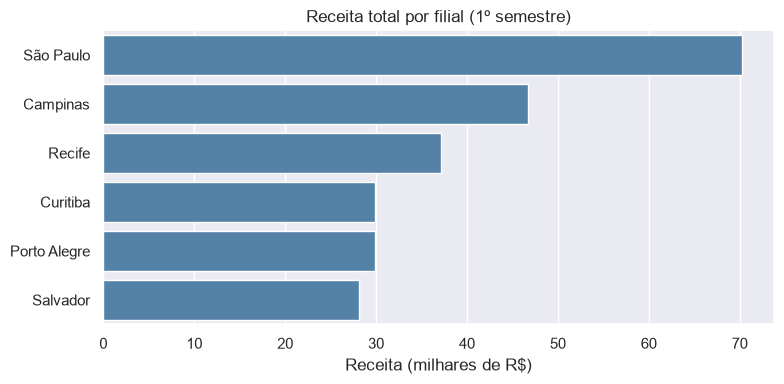

In [33]:
plt.figure(figsize=(8, 4))
sns.barplot(x=resumo_filial["receita_total"] / 1000, y=resumo_filial.index, color="steelblue")
plt.title("Receita total por filial (1º semestre)")
plt.xlabel("Receita (milhares de R$)")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 9.2 Mapa de calor: filial × categoria
Um `pivot_table` sem a linha e a coluna de total vira um mapa de calor. `annot=True` escreve o número em cada célula.

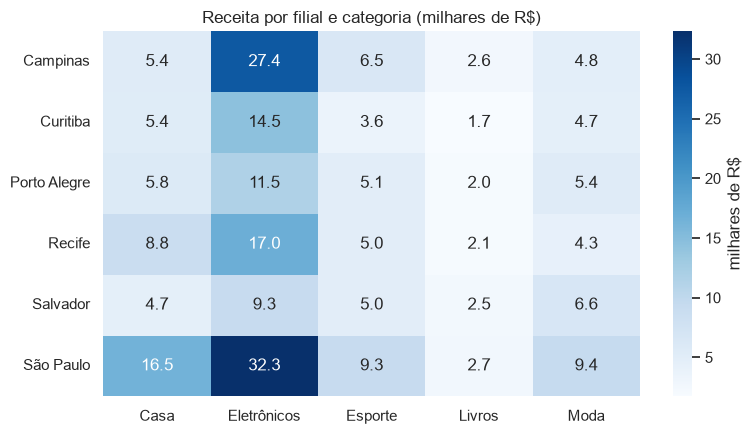

In [34]:
calor = df.pivot_table(index="filial", columns="categoria", values="receita", aggfunc="sum") / 1000

plt.figure(figsize=(8, 4.5))
sns.heatmap(calor, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "milhares de R$"})
plt.title("Receita por filial e categoria (milhares de R$)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

### 9.3 Linhas: evolução mensal por canal
O `mes_canal` da Parte 7.2 já está no formato certo: o índice (meses) vira o eixo x e cada coluna vira uma linha.

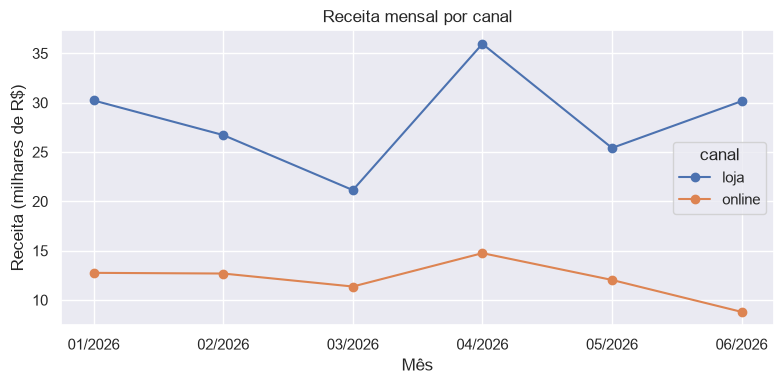

In [35]:
grafico = mes_canal / 1000
grafico.index = grafico.index.strftime("%m/%Y")   # rótulos 01/2026, 02/2026... (sem nomes de mês em inglês)
ax = grafico.plot(figsize=(8, 4), marker="o")
ax.set_title("Receita mensal por canal")
ax.set_xlabel("Mês")
ax.set_ylabel("Receita (milhares de R$)")
plt.tight_layout()
plt.show()

## Parte 10: Exercícios

Tente fazer sozinho antes de olhar as dicas. Use `df` ou recarregue `vendas_rede.csv`.

1. **Básico:** qual categoria vendeu mais **itens** (`quantidade`)? E qual teve a maior **receita**? São a mesma?
2. **size × count:** qual vendedor tem mais vendas **sem receita registrada**? *(Dica: `size()` menos `count()`.)*
3. **agg nomeado:** por `regiao`, calcule número de vendas, receita total, ticket médio e ticket mediano.
4. **Função própria:** por `filial`, calcule a **receita da maior venda dividida pela mediana** (quanto a maior venda é "fora da curva").
5. **transform:** crie a coluna `part_vendedor_pct`, a participação de cada vendedor na receita **da sua filial**. *(Dica: primeiro agrupe por filial e vendedor; depois use `transform` por filial.)*
6. **filter:** mantenha só as categorias com receita total acima de R$ 40.000.
7. **pivot_table:** monte a tabela de **ticket médio** por `categoria` (linhas) e `canal` (colunas), com totais. Onde o online tem ticket maior que a loja?
8. **Tempo:** receita por **semana** (`freq="W"`). Qual foi a melhor semana do semestre?

---

### Resumo do fluxo (cole na parede! 📌)

1. **Dividir**: `df.groupby("coluna")` ou `groupby(["col1", "col2"])`
2. **Resumir**: `sum`, `mean`, `median`, `count` (sem nulos), `size` (com nulos)
3. **Vários resumos**: `agg(nome=("coluna", "função"))`
4. **Tabela simples**: `reset_index()` ou `as_index=False`
5. **Dupla entrada**: `unstack()`, `pivot_table(...)`, `crosstab(...)`
6. **Manter o tamanho**: `transform` (participação, diferença para a média)
7. **Selecionar grupos**: `filter(lambda t: ...)`
8. **Tempo**: `dt.to_period("M")` ou `pd.Grouper(key="data", freq="ME")`
9. **Evitar laços**: prefira operações vetorizadas a `iterrows` e `apply`

---

## Referências

- [1] Wickham, H. (2011). The Split-Apply-Combine Strategy for Data Analysis. *Journal of Statistical Software*, 40(1), 1–29. https://doi.org/10.18637/jss.v040.i01
- [2] Chamberlin, D. D., & Boyce, R. F. (1974). SEQUEL: A Structured English Query Language. *Proceedings of the 1974 ACM SIGFIDET Workshop on Data Description, Access and Control*, 249–264.
- [3] Gray, J., Chaudhuri, S., Bosworth, A., Layman, A., Reichart, D., Venkatrao, M., Pellow, F., & Pirahesh, H. (1997). Data Cube: A Relational Aggregation Operator Generalizing Group-By, Cross-Tab, and Sub-Totals. *Data Mining and Knowledge Discovery*, 1(1), 29–53.
- [4] Wickham, H. (2014). Tidy Data. *Journal of Statistical Software*, 59(10), 1–23. https://doi.org/10.18637/jss.v059.i10
- [5] Harris, C. R., Millman, K. J., van der Walt, S. J., et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
- [6] McKinney, W. (2022). *Python for Data Analysis* (3ª ed.). O'Reilly. Capítulo 10: agregação de dados e operações em grupo. Gratuito em https://wesmckinney.com/book/

### 📖 Para continuar estudando (gratuitos)
- Guia oficial do pandas sobre `groupby`: https://pandas.pydata.org/docs/user_guide/groupby.html
- Guia oficial do pandas sobre `pivot_table`, `melt` e `crosstab`: https://pandas.pydata.org/docs/user_guide/reshaping.html